## Student's depression detection model

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


In [2]:
df = pd.read_csv("Student_Depression_Dataset.csv", encoding="utf-8")

In [3]:
df

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No


In [5]:
df.isnull().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Age,4464.0,22.619176,2.022980,17.00,21.00,23.00,24.0,28.0
Current_semester,4464.0,5.401210,2.578476,0.00,3.00,5.00,7.0,13.0
CGPA,4464.0,3.412753,0.385605,2.25,3.15,3.49,3.7,4.0
Cost_without_study,4464.0,11242.978271,6640.144019,0.00,6100.00,9500.00,15439.0,32000.0


In [10]:
# visualization of the data
df["Gender"]

0       Female
1         Male
2         Male
3         Male
4       Female
         ...  
4459    Female
4460      Male
4461    Female
4462    Female
4463    Female
Name: Gender, Length: 4464, dtype: str

In [11]:
df['Gender'].value_counts()

Gender
Female    2462
Male      2002
Name: count, dtype: int64

<Axes: xlabel='Gender'>

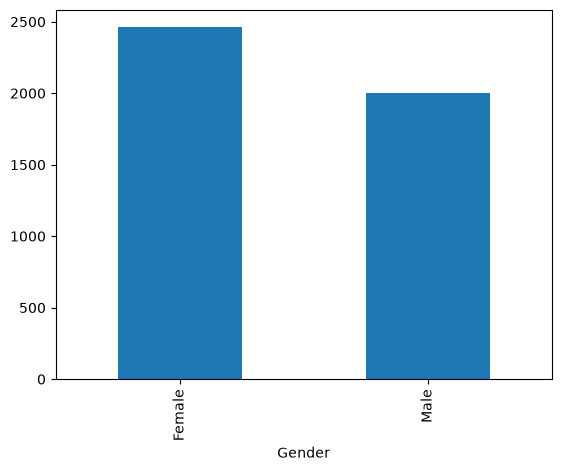

In [12]:
df['Gender'].value_counts().plot(kind="bar")

In [13]:
df['Age'].min()

np.int64(17)

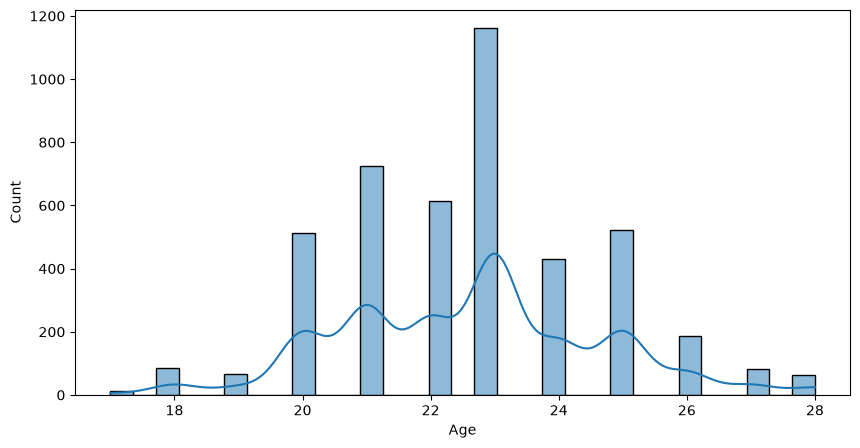

In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Age", kde=True)
plt.show()

In [18]:
df['Family_background'].value_counts()

Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64

<Axes: >

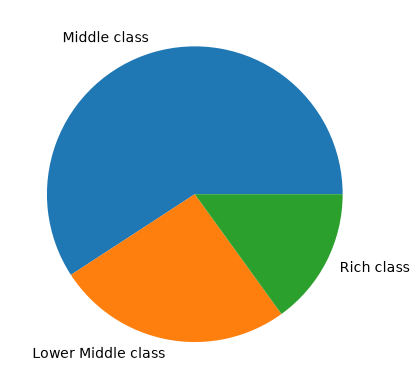

In [20]:
df['Family_background'].value_counts().plot(kind="pie")

In [22]:
df["Relationship_status"].value_counts()

Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64

In [23]:
df.groupby(["Gender", "Relationship_status"])["Age"].mean()

Gender  Relationship_status
Female  Complicated            22.479592
        In a Relationship      23.058277
        Single                 22.712712
Male    Complicated            21.971698
        In a Relationship      22.611722
        Single                 22.282810
Name: Age, dtype: float64

<Axes: xlabel='Gender,Relationship_status'>

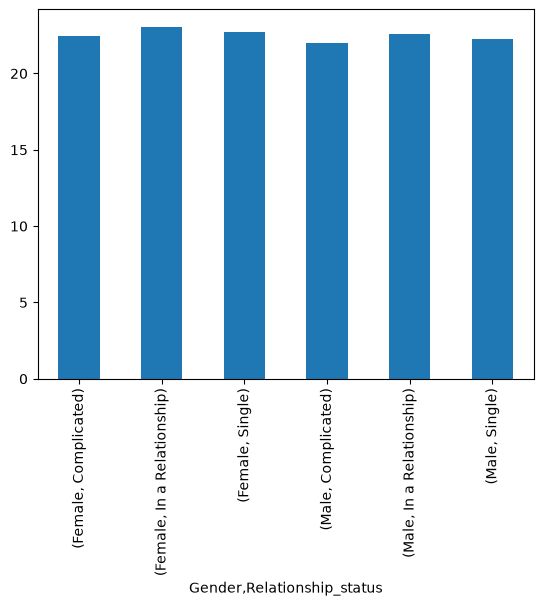

In [28]:
df.groupby(["Gender", "Relationship_status"])["Age"].mean().plot(kind="bar")

In [29]:
df.groupby(["Relationship_status", "CGPA"])['Age'].mean()

Relationship_status  CGPA
Complicated          2.33    21.000000
                     2.40    21.000000
                     2.50    18.000000
                     2.51    25.000000
                     2.53    18.000000
                               ...    
Single               3.96    22.000000
                     3.97    22.000000
                     3.98    21.615385
                     3.99    21.714286
                     4.00    21.386667
Name: Age, Length: 403, dtype: float64

<Axes: xlabel='Relationship_status,CGPA'>

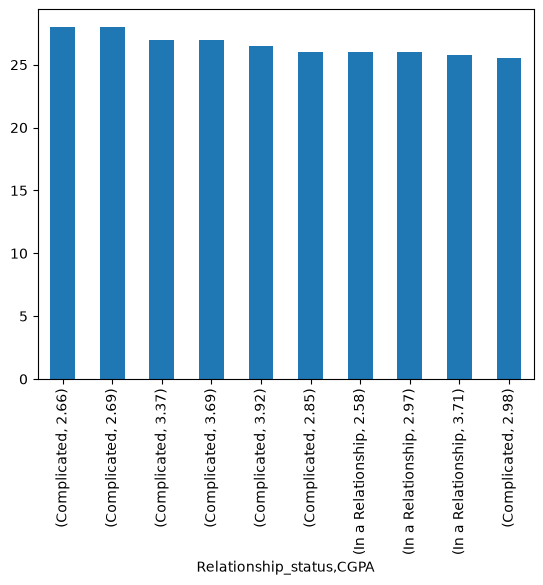

In [35]:
df.groupby(["Relationship_status", "CGPA"])['Age'].mean().nlargest(10).plot(kind="bar")

In [36]:
df.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='str')

In [38]:
df['Marital_status'].value_counts()

Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

In [40]:
fig = px.scatter(data_frame=df, x="Marital_status", y="Depression")
fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed